<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/HW/01RAD_Ex04_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TEAM:**

- Martin Satranský - kód
- Jan Chrastina - popisky
- Veronika Růžičková - double-check & sanity-check

# 01RAD - Homework 04 (team work): The linear algebra of house prices

The file `sarasota_houses_mod.csv` contains 1057 houses sold in one region of the USA with the sale price and a few characteristics:

| column | description |
| --- | --- |
| `price` | sale price in USD |
| `living_area` | interior living area in square feet |
| `bathrooms` | number of bathrooms (can be fractional) |
| `bedrooms` | number of bedrooms |
| `fireplaces` | number of fireplaces |
| `lot_size` | lot size in acres |
| `age` | age of the house in years |
| `fireplace` | indicator whether the house has at least one fireplace |

The homework applies Lecture 4 and Exercise 04 to a real data set: the model matrix, the normal equations as orthogonality, the projection matrices $\mathbf{H}$ and $\mathbf{M}$, reparametrisation, the Frisch–Waugh–Lovell theorem, rank deficiency, and the numerics of least squares (QR, SVD, condition number). Tasks 09 and 10 use Lecture 5 and Exercise 05: the distribution of $\widehat{\boldsymbol{\beta}}$ (Theorems 3.4 and 3.5), dummy variables and interactions. Most tasks can be checked against `statsmodels`; the point is to understand *why* the numbers come out as they do. Write a short answer in a markdown cell after each task.

## Team work
This homework is larger than the previous ones and is solved **in teams of two or three students**. Split the tasks as you like, but every member should be able to explain every answer. At the top of the notebook list the team members and, in one line each, who did what.

## Submission
**Deadline: Sunday 1 November 2026, 23:59** (two weeks, after Exercise 05). Submit through GitHub as before: fork `francji1/01RAD`, save **one notebook per team** into the `HW/` folder as `01RAD_Ex04_HW_<Surname1>_<Surname2>.ipynb` (surnames of all members joined by an underscore, without the brackets, for example `01RAD_Ex04_HW_Novak_Svoboda.ipynb`) and open one pull request to `main`. The pull request should add your one file only; do not modify or delete other files. Python or R, as you prefer.

Useful calls: `patsy.dmatrices`, `np.linalg.qr`, `np.linalg.svd`, `np.linalg.matrix_rank`, `np.linalg.cond`, `scipy.linalg.solve_triangular`, `sm.OLS(y, X).fit()` and `.fit(method='qr')`, `model.df_model`, `model.scale`, `model.get_influence().hat_matrix_diag`.

## Data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.linalg as sla
import statsmodels.api as sm
import statsmodels.formula.api as smf
from patsy import dmatrices

sns.set_theme(style='whitegrid', palette='deep')

url_houses = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/sarasota_houses_mod.csv'
houses = pd.read_csv(url_houses)
print(f'Rows: {houses.shape[0]}, columns: {houses.shape[1]}')
houses.describe().T

Rows: 1057, columns: 8


,count,mean,std,min,25%,50%,75%,max
price,1055.0,167687.885308,77067.890275,16858.0,112276.50,152112.00,206496.00,599701.0
living_area,1057.0,1819.497635,662.941385,672.0,1342.00,1675.00,2223.00,5228.0
bathrooms,1057.0,1.928571,0.650144,1.0,1.50,2.00,2.50,4.5
bedrooms,1057.0,3.184484,0.740486,1.0,3.00,3.00,4.00,5.0
fireplaces,1057.0,0.624409,0.550387,0.0,0.00,1.00,1.00,4.0
lot_size,1048.0,0.570048,0.766297,0.0,0.21,0.39,0.61,9.0
age,1057.0,28.089877,34.928017,0.0,6.00,18.00,34.00,247.0


## Task 01 - Data and the model matrix
Check the missing values and remove the houses with a missing `price` (the column `lot_size` is not used in this homework, so its missing values do not matter). For the model

`price ~ living_area + bathrooms + bedrooms + age + fireplace`

build the model matrix $\mathbf{X}$ once by hand with numpy and once with `dmatrices`, and check that they agree. State $n$, $m+1$, the rank $h(\mathbf{X})$, and what the column for `fireplace` contains.

In [ ]:
# Missing values, drop houses without price (lot_size is not used)
print(houses.isna().sum())
df = houses.dropna(subset=['price']).reset_index(drop=True)

# Model matrix by hand: intercept, living_area, bathrooms, bedrooms, age, fireplace (0/1)
y = df['price'].to_numpy(dtype=float)
X = np.column_stack([
    np.ones(len(df)),
    df['living_area'],
    df['bathrooms'],
    df['bedrooms'],
    df['age'],
    df['fireplace'].astype(float),
])
names = ['Intercept', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace']

# Model matrix with patsy
y_p, X_p = dmatrices('price ~ living_area + bathrooms + bedrooms + age + fireplace',
                     data=df, return_type='dataframe')
print(list(X_p.columns))   # patsy puts fireplace[T.True] right after the intercept

# Compare (reorder the patsy columns to my order)
X_p = X_p[['Intercept', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace[T.True]']]
print('X agrees:', np.allclose(X, X_p.to_numpy()))
print('y agrees:', np.allclose(y, y_p.to_numpy().ravel()))

# Dimensions and rank
n, p = X.shape
print(f'n = {n}, m+1 = {p}, rank h(X) = {np.linalg.matrix_rank(X)}')

# Content of the fireplace column
print(df['fireplace'].unique())
print(np.unique(X[:, 5], return_counts=True))

price          2
living_area    0
bathrooms      0
bedrooms       0
fireplaces     0
lot_size       9
age            0
fireplace      0
dtype: int64
['Intercept', 'fireplace[T.True]', 'living_area', 'bathrooms', 'bedrooms', 'age']
X agrees: True
y agrees: True
n = 1055, m+1 = 6, rank h(X) = 6
[False  True]
(array([0., 1.]), array([428, 627]))


- Missing values: `price` ve 2 řádcích, `lot_size` v 9. Odstraněny jsou jen domy bez ceny 
- `lot_size` v modelu není, n = 1055.
- Ruční X a `dmatrices` se shodují (po přeházení sloupců, patsy dává `fireplace[T.True]` hned za intercept). Shodují se i y.
- n = 1055, m + 1 = 6, h(X) = 6, tj. plná sloupcová hodnost, takže β̂ je jednoznačný.
- `fireplace`: indikátor 0/1 (1 = aspoň jeden krb), 428× 0 a 627× 1. Patsy ho jako bool kóduje jako dummy s referencí False. Koeficient u `fireplace` říká, o kolik je očekávaná cena domu s krbem vyšší při stejných ostatních regresorech.

## Task 02 - Your own least squares
Write a function `my_ols(X, y)` that uses **only** the QR decomposition (`np.linalg.qr` and a triangular solver, no inverse, no `lstsq`) and returns $\widehat{\boldsymbol{\beta}}$, $\widehat{\mathbf{y}}$, $\widehat{\mathbf{e}}$, $s_n^2$ and the leverages $h_{ii}$. Hint: $\mathbf{H} = \mathbf{Q}\mathbf{Q}^T$, so $h_{ii}$ is the squared norm of the $i$-th row of $\mathbf{Q}$; do not build the $n \times n$ matrix.

Apply it to the model of Task 01 and compare $\widehat{\boldsymbol{\beta}}$, $s_n^2$ (`model.scale`), $R^2$ and $h_{ii}$ (`hat_matrix_diag`) with `statsmodels`. Verify numerically $\mathbf{X}^T\widehat{\mathbf{e}} = \mathbf{0}$, $\sum_i h_{ii} = m+1$, $\|\mathbf{y}\|^2 = \|\widehat{\mathbf{y}}\|^2 + \|\widehat{\mathbf{e}}\|^2$ and $R^2 = \mathrm{corr}^2(\mathbf{y}, \widehat{\mathbf{y}})$.

In [ ]:
def my_ols(X, y):
    """OLS via QR only: no inverse, no lstsq."""
    n, p = X.shape
    Q, R = np.linalg.qr(X)                      # reduced QR: Q is n x p, R is p x p
    beta = sla.solve_triangular(R, Q.T @ y)     # solve R beta = Q^T y (back substitution)
    y_hat = X @ beta
    e_hat = y - y_hat
    s2 = e_hat @ e_hat / (n - p)                # s_n^2 = RSS / (n - m - 1)
    h = np.sum(Q**2, axis=1)                    # h_ii = squared norm of row i of Q
    return beta, y_hat, e_hat, s2, h

beta, y_hat, e_hat, s2, h = my_ols(X, y)
n, p = X.shape

# Comparison with statsmodels
model = sm.OLS(y, X).fit()
R2 = 1 - (e_hat @ e_hat) / np.sum((y - y.mean())**2)

print('beta  equal:', np.allclose(beta, model.params))
print('s_n^2 equal:', np.allclose(s2, model.scale), s2, model.scale)
print('R^2   equal:', np.allclose(R2, model.rsquared), R2, model.rsquared)
print('h_ii  equal:', np.allclose(h, model.get_influence().hat_matrix_diag))
print(pd.DataFrame({'my_ols': beta, 'statsmodels': model.params}, index=names))

# Numerical checks
print('\nmax |X^T e|         :', np.abs(X.T @ e_hat).max())   # ~0 relative to the scale of X and y
print('sum h_ii, m+1       :', h.sum(), p)
print('||y||^2             :', y @ y)
print('||y_hat||^2+||e||^2 :', y_hat @ y_hat + e_hat @ e_hat)
print('corr^2(y, y_hat)   :', np.corrcoef(y, y_hat)[0, 1]**2, ' R^2:', R2)

beta  equal: True
s_n^2 equal: True 2367792982.076922 2367792982.076922
R^2   equal: True 0.6032365430430029 0.6032365430430029
h_ii  equal: True
                   my_ols   statsmodels
Intercept    15313.400534  15313.400534
living_area     74.840807     74.840807
bathrooms    18945.193811  18945.193811
bedrooms     -6582.792908  -6582.792908
age           -141.106232   -141.106232
fireplace     7889.161957   7889.161957

max |X^T e|         : 0.00013277679681777954
sum h_ii, m+1       : 6.000000000000001 6
||y||^2             : 35925974893251.0
||y_hat||^2+||e||^2 : 35925974893251.016
corr^2(y, y_hat)   : 0.6032365430430023  R^2: 0.6032365430430029


- `my_ols`: X = QR, z normálních rovnic R β = Qᵀy (zpětná substituce, bez inverze), h_ii = ‖i-tý řádek Q‖², protože H = QQᵀ.
- β̂, s_n² (= 2,37·10⁹, s_n ≈ 48 660 USD), R² (= 0,603) i h_ii se shodují se statsmodels.
- Xᵀê ≈ 0: max 1,3·10⁻⁴, relativně vůči měřítku Xᵀ a ê ~10⁻¹⁵
- Σ h_ii = 6 = m + 1 = tr(H) = tr(QᵀQ).
- ‖y‖² = ‖ŷ‖² + ‖ê‖² (Pythagoras, ŷ ⊥ ê).
- R² = corr²(y, ŷ) = 0,603 (platí díky interceptu).

## Task 03 - Units and reparametrisation
We now want the price in **thousands of USD**, the living area in **square metres** ($1\ \mathrm{ft}^2 = 0.09290304\ \mathrm{m}^2$) and the age **centred** at its mean.

1. Show that the new model matrix is $\widetilde{\mathbf{X}} = \mathbf{X}\mathbf{A}$ for a regular matrix $\mathbf{A}$ and write $\mathbf{A}$ explicitly. With $\widetilde{\mathbf{y}} = c\,\mathbf{y}$, derive $\widetilde{\boldsymbol{\beta}} = c\,\mathbf{A}^{-1}\widehat{\boldsymbol{\beta}}$ from the normal equations.
2. **Before fitting**, compute the new coefficients from the old ones with this formula. Then fit the new model and compare.
3. Which of the following change and how: $\widehat{\mathbf{y}}$, $\widehat{\mathbf{e}}$, $s_n$, $R^2$, $h_{ii}$, $\kappa(\mathbf{X})$? Explain with $\mathbf{H}$.
4. Interpret the intercept of the new model in one sentence. Why is the intercept of the original model hard to interpret?

In [ ]:
c = 1 / 1000                      # USD -> thousands of USD
f = 0.09290304                    # ft^2 -> m^2
age_mean = df['age'].mean()

# X_new = X A: area scaled by f, age shifted by a multiple of the intercept column
A = np.eye(6)
A[1, 1] = f
A[0, 4] = -age_mean
print("Matrix A: ")
print(pd.DataFrame(A, index=names, columns=names).round(4))

X_new = X @ A
y_new = c * y

X_direct = np.column_stack([
    np.ones(len(df)),
    f * df['living_area'],
    df['bathrooms'],
    df['bedrooms'],
    df['age'] - age_mean,
    df['fireplace'].astype(float),
])
print('X A == directly built matrix:', np.allclose(X_new, X_direct))

# Coefficients from the formula, BEFORE fitting
beta_formula = c * np.linalg.solve(A, beta)          # beta_tilde = c A^{-1} beta_hat

# Fit the new model
beta_n, y_hat_n, e_hat_n, s2_n, h_n = my_ols(X_new, y_new)
print(pd.DataFrame({'formula c*A^-1*beta': beta_formula, 'refit': beta_n}, index=names))
print('formula == refit:', np.allclose(beta_formula, beta_n))

# What changes?
r2 = lambda yy, ee: 1 - ee @ ee / np.sum((yy - yy.mean())**2)
print('y_hat_new = c*y_hat   :', np.allclose(y_hat_n, c * y_hat))
print('e_hat_new = c*e_hat   :', np.allclose(e_hat_n, c * e_hat))
print('s_n  old, new, c*old  :', np.sqrt(s2), np.sqrt(s2_n), c * np.sqrt(s2))
print('R^2  old, new         :', r2(y, e_hat), r2(y_new, e_hat_n))
print('h_ii unchanged        :', np.allclose(h, h_n))
print('kappa(X) old, new     :', np.linalg.cond(X), np.linalg.cond(X_new))

# Intercept
print('mean age:', age_mean, '| new intercept (thousand USD):', beta_n[0])

             Intercept  living_area  bathrooms  bedrooms      age  fireplace
Intercept          1.0       0.0000        0.0       0.0 -28.1185        0.0
living_area        0.0       0.0929        0.0       0.0   0.0000        0.0
bathrooms          0.0       0.0000        1.0       0.0   0.0000        0.0
bedrooms           0.0       0.0000        0.0       1.0   0.0000        0.0
age                0.0       0.0000        0.0       0.0   1.0000        0.0
fireplace          0.0       0.0000        0.0       0.0   0.0000        1.0
X A == directly built matrix: True
             formula c*A^-1*beta      refit
Intercept              11.345707  11.345707
living_area             0.805580   0.805580
bathrooms              18.945194  18.945194
bedrooms               -6.582793  -6.582793
age                    -0.141106  -0.141106
fireplace               7.889162   7.889162
formula == refit: True
y_hat_new = c*y_hat   : True
e_hat_new = c*e_hat   : True
s_n  old, new, c*old  : 48659.9730998

- X̃ = XA, A = I kromě A₁₁ = f = 0,0929 (ft² → m²) a A₀₄ = −ā = −28,12 (age − ā = age − ā·1). A je regulární.
- Normální rovnice: AᵀXᵀXA β̃ = c AᵀXᵀy ⇒ XᵀX(Aβ̃) = c Xᵀy ⇒ Aβ̃ = c β̂ ⇒ β̃ = c A⁻¹β̂.
- Koeficienty ze vzorce (před fitem) se shodují s přefitovaným modelem: plocha 0,806 tis. USD/m², intercept 11,35, ostatní β̂/1000.
- C(XA) = C(X), proto H̃ = H:
  - ŷ a ê se násobí c, s_n také (48 660 USD → 48,66 tis.),
  - R² a h_ii se nemění,
  - κ(X) se změní (9 881 → 880), protože závisí na měřítku sloupců, hlavně díky přeškálování plochy.
- Nový intercept: očekávaná cena (tis. USD) domu průměrného stáří (28 let) bez krbu při nulové ploše, koupelnách a ložnicích.
- Původní intercept odpovídá domu s 0 ft², 0 koupelnami a 0 ložnicemi. Nic takového v datech není (min. 672 ft²), jde o extrapolaci.

## Task 04 - The bedroom paradox
Fit the simple regression `price ~ bedrooms` and compare its slope with the coefficient of `bedrooms` in the model of Task 01. The signs differ.

1. Verify the Frisch–Waugh–Lovell theorem for `bedrooms`: compute $\mathbf{M}_{-j}\mathbf{x}_j$ and $\mathbf{M}_{-j}\mathbf{y}$ (residuals of the regressions of `bedrooms` and of `price` on the other columns) and show that the slope of one on the other equals the multiple regression coefficient.
2. Draw both scatter plots (raw and cleaned) with their lines.
3. How much of the variability of `bedrooms` is explained by the other regressors ($R^2$ of the auxiliary regression)?
4. Explain the paradox in plain words for a real estate agent: what does the negative coefficient say about two houses that differ in the number of bedrooms but **not** in the other variables?

slope of bedrooms, simple regression  :    48383.4
coefficient of bedrooms, Task 01 model:    -6582.8
FWL slope of M x_j on M y             :    -6582.8
FWL == multiple regression coefficient: True


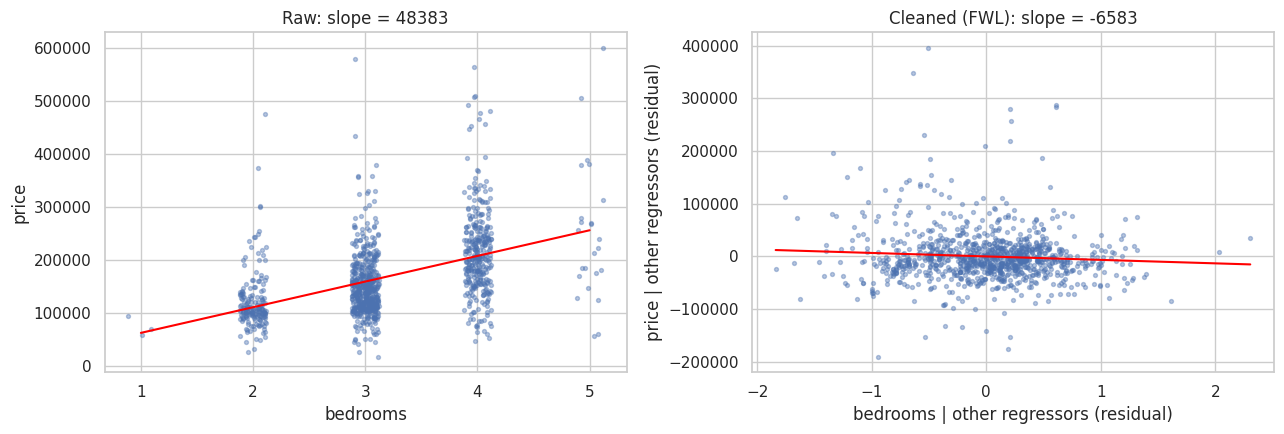

R^2 of bedrooms on the other regressors: 0.457
correlation of bedrooms with living_area: 0.663


In [ ]:
j = 3                                         # column of bedrooms in X
x_bed = X[:, j]

# Simple regression vs multiple regression
X_simple = np.column_stack([np.ones(n), x_bed])
b_simple, yhat_simple, _, _, _ = my_ols(X_simple, y)
print(f'slope of bedrooms, simple regression  : {b_simple[1]:10.1f}')
print(f'coefficient of bedrooms, Task 01 model: {beta[j]:10.1f}')

# 1) Frisch-Waugh-Lovell
X_mj = np.delete(X, j, axis=1)                # all columns except bedrooms
x_tilde = my_ols(X_mj, x_bed)[2]              # M_{-j} x_j
y_tilde = my_ols(X_mj, y)[2]                  # M_{-j} y
slope_fwl = (x_tilde @ y_tilde) / (x_tilde @ x_tilde)
print(f'FWL slope of M x_j on M y             : {slope_fwl:10.1f}')
print('FWL == multiple regression coefficient:', np.allclose(slope_fwl, beta[j]))

# 2) Scatter plots (raw and cleaned), bedrooms jittered a little
rng = np.random.default_rng(0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

xs = np.array([x_bed.min(), x_bed.max()])
ax[0].scatter(x_bed + rng.uniform(-0.12, 0.12, n), y, s=8, alpha=0.4)
ax[0].plot(xs, b_simple[0] + b_simple[1] * xs, color='red')
ax[0].set(xlabel='bedrooms', ylabel='price', title=f'Raw: slope = {b_simple[1]:.0f}')

xt = np.array([x_tilde.min(), x_tilde.max()])
ax[1].scatter(x_tilde, y_tilde, s=8, alpha=0.4)
ax[1].plot(xt, slope_fwl * xt, color='red')
ax[1].set(xlabel='bedrooms | other regressors (residual)', ylabel='price | other regressors (residual)',
          title=f'Cleaned (FWL): slope = {slope_fwl:.0f}')
plt.tight_layout()
plt.show()

# 3) R^2 of the auxiliary regression of bedrooms on the other columns
e_aux = x_tilde
R2_aux = 1 - (e_aux @ e_aux) / np.sum((x_bed - x_bed.mean())**2)
print(f'R^2 of bedrooms on the other regressors: {R2_aux:.3f}')
print(f'correlation of bedrooms with living_area: {np.corrcoef(x_bed, X[:, 1])[0, 1]:.3f}')

- Jednoduchá regrese: sklon +48 383 USD/ložnici, vícenásobná (Task 01): −6 583 USD, znaménko se otočí.
- FWL: rezidua `bedrooms` a `price` po regresi na ostatní sloupce (M₋ⱼxⱼ, M₋ⱼy) dávají sklon x̃ᵀỹ / x̃ᵀx̃ = −6 582,8, shodný s koeficientem vícenásobné regrese.
- Grafy: surová data mají rostoucí trend, po očištění je trend mírně klesající a variabilita ložnic je výrazně menší.
- R² pomocné regrese = 0,457: 46 % variability ložnic vysvětlují ostatní regresory (hlavně plocha, korelace 0,66). VIF ≈ 1,84.
- Pro makléře: domy s více ložnicemi jsou dražší hlavně proto, že jsou větší. Pokud mají dva domy stejnou plochu, koupelny, stáří i krb a liší se jen o jednu ložnici, ten s ložnicí navíc má stejný prostor rozdělený na menší pokoje a prodá se v průměru asi o 6 600 USD levněji. Platí se za plochu, ne za počet ložnic.

## Task 05 - Dummy variables and the trap
1. Add the column `no_fireplace = 1 - fireplace` to the model matrix of Task 01 (keeping the intercept). What is the rank? Fit the model with `sm.OLS(y, X).fit()` and with your `my_ols`. Which coefficients are identified (i.e. are the same for every solution of the normal equations)? Express them through the output. What would R's `lm` report?
2. Now remove the intercept and keep **both** dummies. What is the rank now? Show that this model has exactly the same fitted values as the model of Task 01 and explain why with the column space $\mathcal{M}(\mathbf{X})$. How are the coefficients of the two parametrisations related?
3. Compare the `R-squared` reported by `statsmodels` for the model in 2. with Task 01. In Exercise 03 the model through the origin reported the uncentred $R^2 = \sum_i \widehat{y}_i^2 / \sum_i y_i^2$. Is that the case here? Explain why not (hint: is the vector $\mathbf{1}$ in $\mathcal{M}(\mathbf{X})$?) and what really decides whether a model "has an intercept".

In [ ]:
# 1) Intercept + both dummies: the dummy trap
no_fp = 1 - X[:, 5]
X5 = np.column_stack([X, no_fp])
names5 = names + ['no_fireplace']
print('shape:', X5.shape, ' rank:', np.linalg.matrix_rank(X5))

fit5 = sm.OLS(y, X5).fit()                     # pseudoinverse -> minimum-norm solution
print(pd.Series(fit5.params, index=names5))

try:
    b5 = my_ols(X5, y)[0]
    print('\nmy_ols (QR, R is numerically singular):')
    print(pd.Series(b5, index=names5))
except Exception as ex:
    b5 = None
    print('my_ols fails:', type(ex).__name__, ex)

# Identified (estimable) quantities: the same for every solution of the normal equations
def estimable(b):
    return pd.Series({'living_area': b[1], 'bathrooms': b[2], 'bedrooms': b[3], 'age': b[4],
                      'beta0 + beta_fireplace': b[0] + b[5],
                      'beta0 + beta_no_fireplace': b[0] + b[6],
                      'beta_fireplace - beta_no_fireplace': b[5] - b[6]})
cmp5 = pd.DataFrame({'statsmodels (pinv)': estimable(fit5.params)})
if b5 is not None:
    cmp5['my_ols (QR)'] = estimable(b5)
# another solution of the normal equations: shift along the null space t, X5 t = 0
t_null = np.array([1, 0, 0, 0, 0, -1, -1.0])
cmp5['pinv + 1000*t'] = estimable(fit5.params + 1000 * t_null)
print('\nX5 @ t = 0:', np.allclose(X5 @ t_null, 0))
print(cmp5)
print('fitted values equal Task 01:', np.allclose(fit5.fittedvalues, model.fittedvalues))
print("\nR's lm would report NA for the last coefficient (no_fireplace, 'singularities'), i.e. it drops the last aliased column,")
print("so its beta0 = intercept for houses WITHOUT a fireplace and beta_fireplace = difference fireplace - no fireplace.")

# 2) No intercept, both dummies
X6 = np.column_stack([X[:, 1:5], X[:, 5], no_fp])
names6 = ['living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace', 'no_fireplace']
print('\nrank without intercept, both dummies:', np.linalg.matrix_rank(X6), ' shape:', X6.shape)
fit6 = sm.OLS(y, X6).fit()
print('same fitted values as Task 01:', np.allclose(fit6.fittedvalues, model.fittedvalues))
print(pd.DataFrame({'no intercept, both dummies': fit6.params}, index=names6))
print('\nrelation of the coefficients:')
print('  coef(no_fireplace) = beta0                    :', fit6.params[5], beta[0])
print('  coef(fireplace)    = beta0 + beta_fireplace   :', fit6.params[4], beta[0] + beta[5])
# 1 is in the column space: 1 = fireplace + no_fireplace
print('1 in M(X6):', np.allclose(X6[:, 4] + X6[:, 5], 1))

# 3) R^2
tss_c = np.sum((y - y.mean())**2)
r2_centered = 1 - np.sum(fit6.resid**2) / tss_c
r2_uncentered = np.sum(fit6.fittedvalues**2) / (y @ y)
print('\nR^2 Task 01              :', model.rsquared)
print('R^2 statsmodels, model 2 :', fit6.rsquared)
print('centered R^2 (by hand)   :', r2_centered)
print('uncentered R^2 (by hand) :', r2_uncentered)
print('k_constant detected by statsmodels:', fit6.model.k_constant)

shape: (1055, 7)  rank: 6
Intercept       12838.654342
living_area        74.840807
bathrooms       18945.193811
bedrooms        -6582.792908
age              -141.106232
fireplace       10363.908149
no_fireplace     2474.746192
dtype: float64

my_ols (QR, R is numerically singular):
Intercept      -1.657483e+16
living_area     7.485273e+01
bathrooms       1.894191e+04
bedrooms       -6.585210e+03
age            -1.410151e+02
fireplace       1.657483e+16
no_fireplace    1.657483e+16
dtype: float64

X5 @ t = 0: True
                                    statsmodels (pinv)   my_ols (QR)  \
living_area                                  74.840807     74.852726   
bathrooms                                 18945.193811  18941.913370   
bedrooms                                  -6582.792908  -6585.210071   
age                                        -141.106232   -141.015131   
beta0 + beta_fireplace                    23202.562491  23232.000000   
beta0 + beta_no_fireplace                 15313

/tmp/ipykernel_6988/1321480616.py:7: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit5 = sm.OLS(y, X5).fit()                     # pseudoinverse -> minimum-norm solution


**1.**
- Hodnost 6 ze 7, protože 1 = fireplace + no_fireplace (dummy trap). Řešení jsou β + λt, kde t = (1,0,0,0,0,−1,−1).
- statsmodels (pinv) vrací řešení s minimální normou. my_ols (QR) dělí ≈ 0, takže koeficienty ~10¹⁶ jsou nesmyslné.
- Identifikované: β_living, β_bath, β_bed, β_age; β₀ + β_fp = 23 203; β₀ + β_nofp = 15 313; β_fp − β_nofp = 7 889.
- R `lm`: u `no_fireplace` NA, zbytek jako v Task 01.

**2.**
- Hodnost 6 = plná hodnost.
- M(X₆) = M(X), protože 1 = fp + nofp. Stejné H dává stejné ŷ.
- β_nofp = β₀ = 15 313, β_fp = β₀ + β_fireplace = 23 203, ostatní koeficienty jsou stejné.

**3.**
- R² = 0,603 (centrované, jako v Task 01), ne necentrované 0,931.
- 1 ∈ M(X₆) a statsmodels implicitní konstantu rozpozná.
- O interceptu rozhoduje 1 ∈ M(X), ne explicitní sloupec jedniček.


## Task 06 - Leverage as a data check
Plot the leverages $h_{ii}$ of the model of Task 01 against the observation index and list the ten houses with the largest $h_{ii}$. Compare with the mean leverage $(m+1)/n$.

1. What do the houses with the largest leverage have in common? Look at the variable `age` in particular: how many houses are older than 100 and older than 200 years, and how do they differ from the rest in the other variables? Are such values plausible, and what would you check or ask before using them?
2. Refit the model without the houses with `age` above 150 years and compare the coefficients, in particular the coefficient of `age`. Does the decision matter?
3. Leverage depends only on $\mathbf{X}$. Why is it nevertheless a good tool for finding errors in the data, before the response is even used?

mean leverage (m+1)/n = 0.00569, max h_ii = 0.056


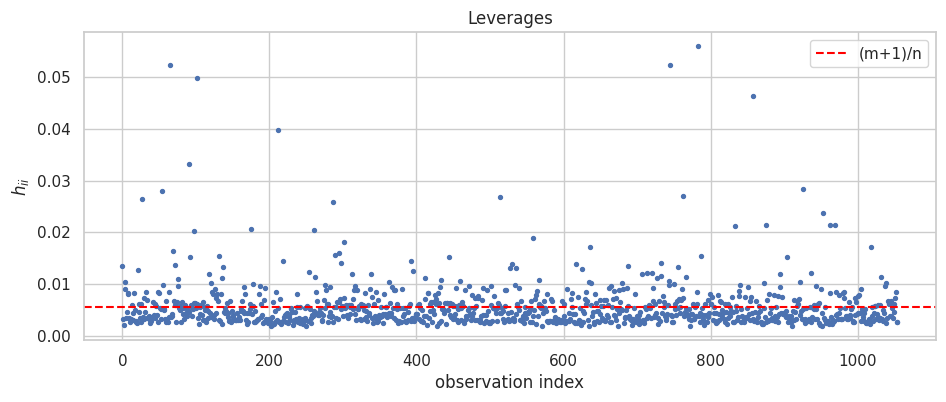

        price  living_area  bathrooms  bedrooms  age  fireplace      h_ii  \
783   88092.0         3944        1.0         4  185       True  0.055933   
745  599701.0         5114        4.5         5  131       True  0.052303   
65   226742.0         1989        2.0         3  247       True  0.052240   
102   59003.0         3285        2.0         5  233      False  0.049844   
857   75975.0         1300        2.0         3  227       True  0.046357   
211  562546.0         5228        4.0         4   14       True  0.039726   
91   185318.0         1500        1.5         4  208       True  0.033288   
925  139627.0         1980        1.0         4  205      False  0.028452   
54   157513.0         2164        2.0         3  183       True  0.028049   
762  139104.0         1760        3.0         4  135      False  0.027108   

     h_over_mean  
783     9.834815  
745     9.196641  
65      9.185504  
102     8.764217  
857     8.151024  
211     6.985131  
91      5.853058  


In [ ]:
# Leverages from Task 02 (h), mean leverage (m+1)/n
print(f'mean leverage (m+1)/n = {p / n:.5f}, max h_ii = {h.max():.3f}')
fig, ax = plt.subplots(figsize=(11, 4))
ax.scatter(np.arange(n), h, s=8)
ax.axhline(p / n, color='red', ls='--', label='(m+1)/n')
ax.set(xlabel='observation index', ylabel='$h_{ii}$', title='Leverages')
ax.legend()
plt.show()

top10 = np.argsort(h)[::-1][:10]
cols = ['price', 'living_area', 'bathrooms', 'bedrooms', 'age', 'fireplace']
print(df.loc[top10, cols].assign(h_ii=h[top10], h_over_mean=h[top10] / (p / n)))

# 1) Old houses
print('\nage > 100:', (df['age'] > 100).sum(), ' age > 200:', (df['age'] > 200).sum())
old = df['age'] > 100
print(pd.DataFrame({'age > 100': df.loc[old, cols].mean(),
                    'age <= 100': df.loc[~old, cols].mean()}))
print(df.loc[df['age'] > 100, cols].sort_values('age', ascending=False))

# 2) Refit without age > 150
keep = (df['age'] <= 150).to_numpy()
print('\nremoved houses:', (~keep).sum())
beta_k, _, _, s2_k, _ = my_ols(X[keep], y[keep])
fit_all = sm.OLS(y, X).fit()
fit_keep = sm.OLS(y[keep], X[keep]).fit()
print(pd.DataFrame({'all': fit_all.params, 'age <= 150': fit_keep.params,
                    'se all': fit_all.bse, 'se age <= 150': fit_keep.bse}, index=names))
print('p-value of age: all =', fit_all.pvalues[4], ', age <= 150 =', fit_keep.pvalues[4])
print('R^2: all =', fit_all.rsquared, ', age <= 150 =', fit_keep.rsquared)

- Několik domů má h_ii řádově vyšší než průměr (m+1)/n. Skoro všechny jsou extrémně staré, jeden je extrémně velký.

**1.**
- Společné mají extrémní `age`.
- Staré domy jsou levnější, menší, mají méně koupelen a méně často krb. Ložnic mají stejně.
- Nad ~150 let jsou jen ojedinělé hodnoty a divné kombinace (velmi starý dům za minimální cenu), proto je stáří podezřelé.
- Ověřit: definici `age` (od stavby, nebo od rekonstrukce?), překlepy, rok stavby v registru, dotaz u zdroje dat.

**2.**
- Koeficient `age` se výrazně zmenší a přestane být významný. Ostatní koeficienty se mění jen mírně.
- Rozhodnutí je podstatné, efekt stáří táhne pár extrémních domů.

**3.**
- h_ii měří vzdálenost xᵢ od středu dat (Mahalanobis). Chyby v X dávají neobvyklé hodnoty, a tedy vysoký h_ii.
- Body s vysokým h_ii mají největší vliv na fit, takže chyba v nich zkreslí koeficienty nejvíc.
- Nepoužívá y, takže rozhodnutí o vyřazení není ovlivněné tím, jak to „vyjde“.


## Task 07 - When the default fails: polynomials in the living area
Fit polynomial models `price` $= \beta_0 + \beta_1 a + \beta_2 a^2 + \dots + \beta_d a^d + e$ in the living area $a$ (square feet, raw) for degrees $d = 1, \dots, 6$, building the columns $a^k$ yourself (`np.vander`). For each degree record in one table:
- $\kappa(\mathbf{X})$ and `np.linalg.matrix_rank(X)`,
- $R^2$ and `df_model` from `sm.OLS(y, X).fit()` (default, pseudoinverse),
- $R^2$ from `sm.OLS(y, X).fit(method='qr')` and from your `my_ols`,
- $R^2$ with the standardized variable $(a - \overline{a})/s_a$ instead of $a$.

1. The models are **nested**: the model of degree $d+1$ contains the model of degree $d$. What does that imply for $R^2$ as $d$ grows (think of the projection onto a larger subspace)? Which column of the table violates this, and from which degree on?
2. Explain what the default method does wrong. Hint: compute the singular values of $\mathbf{X}$, compare them with the tolerance used to decide which ones count as zero (`np.linalg.matrix_rank` uses $s_1 \cdot \max(n, p) \cdot \varepsilon_{\text{machine}}$), and look at `df_model`.
3. Why do QR and the standardized version give the correct answer? Which fix would you use in practice?

In [ ]:
a = df['living_area'].to_numpy(dtype=float)
a_std = (a - a.mean()) / a.std(ddof=1)
r2_from = lambda yy, yh: 1 - np.sum((yy - yh)**2) / np.sum((yy - yy.mean())**2)

rows = []
for d in range(1, 7):
    Xd = np.vander(a, d + 1, increasing=True)          # 1, a, a^2, ..., a^d
    Xz = np.vander(a_std, d + 1, increasing=True)      # same with standardized a
    fit_def = sm.OLS(y, Xd).fit()                      # default: pseudoinverse
    fit_qr = sm.OLS(y, Xd).fit(method='qr')
    b_my, yh_my, _, _, _ = my_ols(Xd, y)
    rows.append({'d': d,
                 'kappa(X)': np.linalg.cond(Xd),
                 'rank': np.linalg.matrix_rank(Xd),
                 'R2 default': fit_def.rsquared,
                 'df_model': fit_def.df_model,
                 'R2 qr': fit_qr.rsquared,
                 'R2 my_ols': r2_from(y, yh_my),
                 'R2 standardized': sm.OLS(y, Xz).fit().rsquared,
                 'kappa std': np.linalg.cond(Xz)})
tab7 = pd.DataFrame(rows).set_index('d')
pd.set_option('display.float_format', lambda v: f'{v:.6g}')
display(tab7)
pd.reset_option('display.float_format')

# R^2 should be non-decreasing in d (nested models)
for col in ['R2 default', 'R2 qr', 'R2 my_ols', 'R2 standardized']:
    dec = [d for d in range(2, 7) if tab7.loc[d, col] < tab7.loc[d - 1, col] - 1e-12]
    print(f'{col:16s}: R^2 decreases at degree(s) {dec}')

# Singular values vs the tolerance used for the rank decision
for d in range(1, 7):
    Xd = np.vander(a, d + 1, increasing=True)
    s_ = np.linalg.svd(Xd, compute_uv=False)
    tol = s_[0] * max(Xd.shape) * np.finfo(float).eps
    print(f'd={d}: smallest singular value = {s_[-1]:.3e}, tolerance = {tol:.3e}, rank = {(s_ > tol).sum()} of {d + 1}')
Xd = np.vander(a, 7, increasing=True)
print('\nsingular values for d=6:', np.linalg.svd(Xd, compute_uv=False))

/tmp/ipykernel_6988/708303497.py:9: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit_def = sm.OLS(y, Xd).fit()                      # default: pseudoinverse
/tmp/ipykernel_6988/708303497.py:9: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit_def = sm.OLS(y, Xd).fit()                      # default: pseudoinverse
/tmp/ipykernel_6988/708303497.py:9: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fit_def = sm.OLS(y, Xd).fit()                      # default: pseudoinverse


,kappa(X),rank,R2 default,df_model,R2 qr,R2 my_ols,R2 standardized,kappa std
d,,,,,,,,
1,5655.65,2,0.57566,1,0.57566,0.57566,0.57566,1.00047
2,3.19897e+07,3,0.582868,2,0.582868,0.582868,0.582868,3.11879
3,1.918e+11,4,0.583051,3,0.583051,0.583051,0.583051,11.7021
4,1.52711e+15,4,0.580213,3,0.587821,0.587821,0.587821,72.6399
5,1.02416e+19,4,0.565239,3,0.587933,0.587933,0.587933,497.291
6,1.62729e+23,4,0.511069,3,0.587967,0.587967,0.587967,3240.31


R2 default      : R^2 decreases at degree(s) [4, 5, 6]
R2 qr           : R^2 decreases at degree(s) []
R2 my_ols       : R^2 decreases at degree(s) []
R2 standardized : R^2 decreases at degree(s) []
d=1: smallest singular value = 1.112e+01, tolerance = 1.473e-08, rank = 2 of 2
d=2: smallest singular value = 4.813e+00, tolerance = 3.607e-05, rank = 3 of 3
d=3: smallest singular value = 2.405e+00, tolerance = 1.081e-01, rank = 4 of 4
d=4: smallest singular value = 1.077e+00, tolerance = 3.852e+02, rank = 4 of 5
d=5: smallest singular value = 6.614e-01, tolerance = 1.587e+06, rank = 4 of 6
d=6: smallest singular value = 1.901e-01, tolerance = 7.247e+09, rank = 4 of 7

singular values for d=6: [3.09353578e+22 1.34481682e+18 9.37098906e+13 1.20458400e+10
 2.58393209e+06 2.34470695e+05 1.90103377e-01]


**1.**
- Vnořené modely: $\mathcal{M}(\mathbf{X}_d) \subset \mathcal{M}(\mathbf{X}_{d+1})$. Projekce na větší podprostor je k $\mathbf{y}$ aspoň tak blízko, takže $\mathrm{RSS}$ neroste a $R^2$ neklesá.
- Porušuje to sloupec `R2 default`, a to od $d = 4$.

**2.**
- Default (pinv přes SVD) bere singulární čísla pod $s_1 \cdot \max(n,p) \cdot \varepsilon$ jako nulová a zahodí je.
- Sloupce $a^k$ mají extrémně různá měřítka, takže $s_1$ je obrovské a tolerance s ním. Od $d = 4$ se pod ni dostanou i skutečně nenulová singulární čísla.
- Hodnost je numericky ořezaná na 4 a `df_model` zůstává 3, i když $\mathbf{X}$ má matematicky plnou hodnost. Nejde o skutečnou kolinearitu, ale o artefakt škálování.
- Ponechané směry odpovídají hlavně vysokým mocninám, ne prostoru polynomů 3. stupně. Fit je proto horší než u nižšího stupně a chybné jsou i stupně volnosti pro testy.

**3.**
- QR pracuje přímo s $\mathbf{X}$ bez prahování a $\widehat{\mathbf{y}} = \mathbf{Q}\mathbf{Q}^T\mathbf{y}$ je stabilní projekce. $\widehat{\boldsymbol\beta}$ může být nepřesné (chyba $\sim \kappa\,\varepsilon$), ale $R^2$ vyjde správně.
- Standardizace $(a - \bar a)/s_a$ je regulární reparametrizace $\widetilde{\mathbf{X}} = \mathbf{X}\mathbf{A}$, takže $\mathcal{M}(\mathbf{X})$ i $\widehat{\mathbf{y}}$ se nemění. Mocniny jsou ale v podobném měřítku a $\kappa$ je řádově menší.
- V praxi: standardizovat/centrovat (nebo ortogonální polynomy, R `poly()`). Kromě správného $R^2$ to dává i stabilní a interpretovatelné $\widehat{\boldsymbol\beta}$.


## Task 08 - Singular values and the variance of the estimates
Take the model of Task 01 with all non-intercept columns standardized (including `fireplace`), so that the coefficients are comparable.

1. Compute the SVD $\mathbf{X} = \mathbf{P}\mathbf{S}\mathbf{Q}^T$, the singular values and $\kappa(\mathbf{X})$. Is there a problem with collinearity in this model?
2. `statsmodels` reports the standard errors $\sqrt{s_n^2\,[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj}}$ (Theorem 3.4 will justify this in the next lecture). Using the SVD, write $[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj} = \sum_k q_{jk}^2/s_k^2$ and compute the standard errors from this formula; compare with `model.bse`.
3. For the coefficient of `bedrooms`, compute the share of each term $q_{jk}^2/s_k^2$ in the sum. Which singular direction contributes most? Which variables have large weights in that direction $\mathbf{q}_k$, and how does it relate to Task 04?

In [ ]:
# Standardize all non-intercept columns (including fireplace)
Z = (X[:, 1:] - X[:, 1:].mean(axis=0)) / X[:, 1:].std(axis=0, ddof=1)
Xs = np.column_stack([np.ones(n), Z])

# 1) SVD  X = P S Q^T
P, S, Qt = np.linalg.svd(Xs, full_matrices=False)
V = Qt.T                                           # columns q_k
print('singular values:', S)
print('kappa(X) =', S[0] / S[-1], ' (np.linalg.cond:', np.linalg.cond(Xs), ')')

# 2) Standard errors from the SVD
fit_s = sm.OLS(y, Xs).fit()
diag_inv = np.sum(V**2 / S**2, axis=1)             # [(X^T X)^{-1}]_jj = sum_k q_jk^2 / s_k^2
se_svd = np.sqrt(fit_s.scale * diag_inv)
print(pd.DataFrame({'SE (SVD)': se_svd, 'model.bse': fit_s.bse, 'beta': fit_s.params}, index=names))
print('SE agree:', np.allclose(se_svd, fit_s.bse))

# 3) Contributions of the singular directions for bedrooms
j = 3
contrib = V[j]**2 / S**2
share = contrib / contrib.sum()
print(pd.DataFrame({'s_k': S, 'q_jk^2': V[j]**2, 'q_jk^2/s_k^2': contrib, 'share': share},
                   index=[f'k={k + 1}' for k in range(len(S))]))
k_max = np.argmax(share)
print(f'\nlargest share: k={k_max + 1} ({share[k_max]:.1%}), s_k = {S[k_max]:.3f}')
print('weights of this direction q_k on the variables:')
print(pd.Series(V[:, k_max], index=names).round(3))
print('correlation matrix of the regressors:')
print(pd.DataFrame(Z, columns=names[1:]).corr().round(2))

singular values: [53.73999861 32.48076354 32.26768325 26.7009766  19.86457394 15.27303891]
kappa(X) = 3.518618588253419  (np.linalg.cond: 3.5186185882534176 )
                SE (SVD)    model.bse           beta
Intercept    1498.116664  1498.116664  167687.885308
living_area  2603.148800  2603.148800   49591.306682
bathrooms    2399.400166  2399.400166   12319.737365
bedrooms     2034.479764  2034.479764   -4870.367590
age          1694.502967  1694.502967   -4932.265210
fireplace    1738.467236  1738.467236    3875.609319
SE agree: True
           s_k    q_jk^2  q_jk^2/s_k^2     share
k=1  53.739999  0.193589      0.000067  0.038346
k=2  32.480764  0.000000      0.000000  0.000000
k=3  32.267683  0.255047      0.000245  0.140127
k=4  26.700977  0.071752      0.000101  0.057572
k=5  19.864574  0.411137      0.001042  0.596025
k=6  15.273039  0.068476      0.000294  0.167930

largest share: k=5 (59.6%), s_k = 19.865
weights of this direction q_k on the variables:
Intercept      0.000
l

**1.**
- $\kappa(\mathbf{X})$ je po standardizaci malé (problém by byl řádově $\gtrsim 30$), takže kolinearita v modelu problém není.
- $s_2 = \sqrt{n}$ odpovídá samotnému interceptu: standardizované sloupce jsou kolmé na $\mathbf{1}$, takže $\mathbf{1}/\sqrt{n}$ je singulární vektor.

**2.**
- $\mathbf{X}^T\mathbf{X} = \mathbf{Q}\mathbf{S}^2\mathbf{Q}^T \Rightarrow (\mathbf{X}^T\mathbf{X})^{-1} = \mathbf{Q}\mathbf{S}^{-2}\mathbf{Q}^T \Rightarrow [(\mathbf{X}^T\mathbf{X})^{-1}]_{jj} = \sum_k q_{jk}^2/s_k^2$.
- $\mathrm{SE}_j = \sqrt{s_n^2 \sum_k q_{jk}^2/s_k^2}$ se shoduje s `model.bse`.

**3.**
- U `bedrooms` tvoří většinu rozptylu směr $k = 5$ s malým $s_k$. Malé $s_k$ znamená velké $1/s_k^2$.
- $\mathbf{q}_5$ je kontrast: `bedrooms` (+) proti `bathrooms`, `living_area` a `age` (−), tedy „víc ložnic při menší ploše a méně koupelnách“.
- Protože $\|\mathbf{X}\mathbf{q}_k\| = s_k$, data se v tomto směru mění málo: domy se zřídka liší počtem ložnic při stejné ploše a koupelnách.
- Souvislost s Task 04: přesně tato „očištěná“ variabilita ložnic ($\mathbf{M}_{-j}\mathbf{x}_j$) určuje $\hat\beta_{bed}$. Ložnice korelují s plochou a koupelnami, takže jí zbývá málo a odhad má větší rozptyl. $s_5$ ale není extrémně malé, kolinearita je jen mírná (viz VIF).


## Task 09 - Theorem 3.4 by simulation
Take the model of Task 01 as the truth: the model matrix $\mathbf{X}$ is fixed (the 1055 houses), the true parameters are $\boldsymbol{\beta} = \widehat{\boldsymbol{\beta}}$ and $\sigma = s_n$ from Task 01. Generate at least 2000 new response vectors $\mathbf{y}^* = \mathbf{X}\boldsymbol{\beta} + \mathbf{e}^*$, $\mathbf{e}^* \sim N_n(\mathbf{0}, \sigma^2\mathbf{I}_n)$, and in each replication compute $\widehat{\boldsymbol{\beta}}^*$ and $s_n^{2*}$ (use your `my_ols`).

1. Compare the mean of $\widehat{\boldsymbol{\beta}}^*$ with $\boldsymbol{\beta}$ and the mean of $s_n^{2*}$ with $\sigma^2$ (Theorem 3.4, points 1 and 3).
2. Compare the empirical covariance matrix of $\widehat{\boldsymbol{\beta}}^*$ with $\sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$: the standard deviations of the coefficients and the correlation matrix.
3. The estimates of the coefficients of `bedrooms` and `living_area` are correlated. Which sign does the correlation have, and why? Draw the scatter plot of the two estimates and relate it to the correlation of the regressors and to Task 04.
4. For `bedrooms`, check that $T = (\widehat{\beta}_j^* - \beta_j)/\big(s_n^*\sqrt{[(\mathbf{X}^T\mathbf{X})^{-1}]_{jj}}\big)$ has the $t(n-m-1)$ distribution (Theorem 3.5): histogram with the density, and the share of replications in which the 95 % confidence interval covers the true $\beta_j$.

                true beta  mean of estimates  rel. diff
Intercept    15313.400534       15212.900436  -0.006563
living_area     74.840807          74.897097   0.000752
bathrooms    18945.193811       18899.218518  -0.002427
bedrooms     -6582.792908       -6567.396655  -0.002339
age           -141.106232        -140.268350  -0.005938
fireplace     7889.161957        7942.567842   0.006770
sigma^2 = 2.36779e+09,  mean of s_n^2* = 2.36824e+09
             empirical sd  theoretical sd     ratio
Intercept     7259.574000     7322.384487  0.991422
living_area      3.936348        3.928547  1.001986
bathrooms     3653.446460     3689.778429  0.990153
bedrooms      2738.058492     2749.804550  0.995728
age             48.398220       48.477711  0.998360
fireplace     3467.153623     3538.811180  0.979751

max |corr_emp - corr_theory| = 0.025425288358063285
theoretical correlation matrix:
             Intercept  living_area  bathrooms  bedrooms   age  fireplace
Intercept         1.00         0

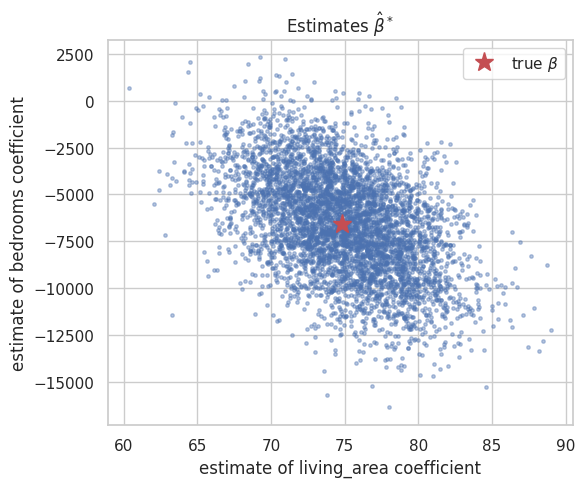

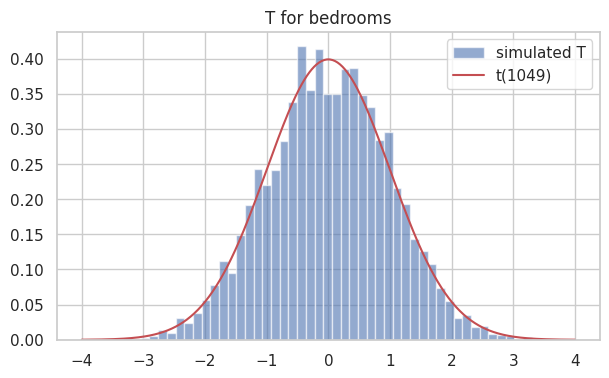

coverage of the 95 % CI: 0.9550
KS test of T vs t: KstestResult(statistic=np.float64(0.01408138646310686), pvalue=np.float64(0.272087290928145), statistic_location=np.float64(0.25621219588970956), statistic_sign=np.int8(-1))


In [ ]:
from scipy import stats

rng = np.random.default_rng(2026)
R = 5000                                           # replications
sigma = np.sqrt(s2)
beta_true = beta.copy()
Xb = X @ beta_true                                 # X is fixed

B = np.empty((R, p))
S2 = np.empty(R)
for r in range(R):
    y_star = Xb + rng.normal(0, sigma, n)
    B[r], _, _, S2[r], _ = my_ols(X, y_star)

XtX_inv = np.linalg.inv(X.T @ X)
cov_theory = s2 * XtX_inv                          # sigma^2 (X^T X)^{-1}, sigma^2 = s_n^2 of Task 01

# 1) Means (Theorem 3.4, points 1 and 3)
print(pd.DataFrame({'true beta': beta_true, 'mean of estimates': B.mean(axis=0),
                    'rel. diff': B.mean(axis=0) / beta_true - 1}, index=names))
print(f'sigma^2 = {s2:.6g},  mean of s_n^2* = {S2.mean():.6g}')

# 2) Covariance matrix: standard deviations and correlations
cov_emp = np.cov(B, rowvar=False)
sd_emp, sd_th = np.sqrt(np.diag(cov_emp)), np.sqrt(np.diag(cov_theory))
print(pd.DataFrame({'empirical sd': sd_emp, 'theoretical sd': sd_th, 'ratio': sd_emp / sd_th}, index=names))
corr_th = cov_theory / np.outer(sd_th, sd_th)
print('\nmax |corr_emp - corr_theory| =', np.abs(np.corrcoef(B, rowvar=False) - corr_th).max())
print('theoretical correlation matrix:')
print(pd.DataFrame(corr_th, index=names, columns=names).round(2))
print('empirical correlation matrix:')
print(pd.DataFrame(np.corrcoef(B, rowvar=False), index=names, columns=names).round(2))

# 3) bedrooms (3) vs living_area (1)
jb, ja = 3, 1
print(f'\ncorr of estimates (bedrooms, living_area): empirical {np.corrcoef(B[:, jb], B[:, ja])[0, 1]:.3f}, '
      f'theoretical {corr_th[jb, ja]:.3f}')
print(f'corr of the regressors (bedrooms, living_area): {np.corrcoef(X[:, jb], X[:, ja])[0, 1]:.3f}')
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(B[:, ja], B[:, jb], s=6, alpha=0.4)
ax.plot(beta_true[ja], beta_true[jb], 'r*', ms=14, label='true $\\beta$')
ax.set(xlabel='estimate of living_area coefficient', ylabel='estimate of bedrooms coefficient',
       title='Estimates $\\hat\\beta^*$')
ax.legend()
plt.show()

# 4) T statistic for bedrooms ~ t(n - m - 1), 95 % confidence interval coverage
T = (B[:, jb] - beta_true[jb]) / (np.sqrt(S2) * np.sqrt(XtX_inv[jb, jb]))
dfree = n - p
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(T, bins=50, density=True, alpha=0.6, label='simulated T')
grid = np.linspace(-4, 4, 400)
ax.plot(grid, stats.t.pdf(grid, dfree), 'r', label=f't({dfree})')
ax.legend()
ax.set(title='T for bedrooms')
plt.show()

tq = stats.t.ppf(0.975, dfree)
half = tq * np.sqrt(S2) * np.sqrt(XtX_inv[jb, jb])
covered = (B[:, jb] - half <= beta_true[jb]) & (beta_true[jb] <= B[:, jb] + half)
print(f'coverage of the 95 % CI: {covered.mean():.4f}')
print('KS test of T vs t:', stats.kstest(T, 't', args=(dfree,)))

**1.**
- Průměry $\widehat{\boldsymbol\beta}^*$ se shodují s $\boldsymbol\beta$ a průměr $s_n^{2*}$ se shoduje se $\sigma^2$, odchylky jsou v rámci Monte Carlo chyby ($\mathrm{sd}/\sqrt{R}$).
- To odpovídá Větě 3.4: $\mathrm{E}\,\widehat{\boldsymbol\beta} = \boldsymbol\beta$ a $\mathrm{E}\,s_n^2 = \sigma^2$ (oba odhady jsou nestranné).

**2.**
- Empirické směrodatné odchylky i korelační matice odpovídají $\sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$, poměry sd jsou $\approx 1$. Platí tedy $\mathrm{var}\,\widehat{\boldsymbol\beta} = \sigma^2(\mathbf{X}^T\mathbf{X})^{-1}$.

**3.**
- Korelace odhadů $\hat\beta_{bed}$ a $\hat\beta_{living}$ je záporná, i když regresory jsou korelované kladně.
- Kladná korelace regresorů dává záporný mimodiagonální prvek $(\mathbf{X}^T\mathbf{X})^{-1}$; pro dva standardizované regresory je přesně $\mathrm{corr}(\hat\beta_1, \hat\beta_2) = -r_{12}$.
- Intuice: obě proměnné nesou společnou informaci o velikosti domu. Když šum v daném vzorku „nadhodnotí“ jeden koeficient, druhý to vykompenzuje dolů a $\widehat{\mathbf{y}}$ ve společném směru zůstane podobné. Proto je mrak bodů v grafu skloněná elipsa.
- Souvislost s Task 04: $\hat\beta_{bed}$ se odhaduje jen z části variability ložnic kolmé na ostatní regresory. Společná část se mezi koeficienty „přelévá“.

**4.**
- Histogram $T$ odpovídá hustotě $t(n-m-1)$ a KS test shodu nezamítá.
- Pokrytí 95% intervalu je $\approx 95\,\%$, v rámci MC chyby $\sqrt{0{,}95 \cdot 0{,}05/R}$.
- To odpovídá Větě 3.5: $\hat\beta_j$ má normální rozdělení, $(n-m-1)s_n^2/\sigma^2 \sim \chi^2_{n-m-1}$ a obojí je nezávislé, takže $T \sim t(n-m-1)$.

## Task 10 - Fireplace: interaction and separate regressions
Fit the model `price ~ living_area * fireplace` (R: `lm(price ~ living_area * fireplace)`).

1. Write the model matrix for this formula: which four columns does it have? Write the two regression lines (houses without and with a fireplace) in terms of the four coefficients and interpret each coefficient in one sentence, including its units.
2. Test whether the price per square foot is the same for houses with and without a fireplace (the $t$-test of the interaction term). State the hypotheses, the statistic, the degrees of freedom and the conclusion. Draw the data with the two fitted lines.
3. Now fit two separate simple regressions `price ~ living_area`, one for the houses with and one for the houses without a fireplace. Compare the coefficients with the lines from 1.: what is equal and why? (Think of the column space of the interaction model and of a model matrix that is block diagonal after reordering the rows.)
4. Compare $s_n$ and the standard errors of the slopes in the interaction model and in the two separate models. Which assumption about $\sigma^2$ makes the difference? Which approach would you prefer here, and what would you check to decide?

['Intercept', 'fireplace[T.True]', 'living_area', 'living_area:fireplace[T.True]']  rank: 4
   Intercept  fireplace[T.True]  living_area  living_area:fireplace[T.True]
0        1.0                0.0       1982.0                            0.0
1        1.0                1.0       1676.0                         1676.0
2        1.0                1.0       1694.0                         1694.0
3        1.0                1.0       1800.0                         1800.0
4        1.0                1.0       2088.0                         2088.0
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept                      4.218e+04   7915.205      5.329      0.000    2.66e+04    5.77e+04
fireplace[T.True]             -3.762e+04   1.03e+04     -3.660      0.000   -5.78e+04   -1.74e+04
living_area                      59.7433      5.257     11.3

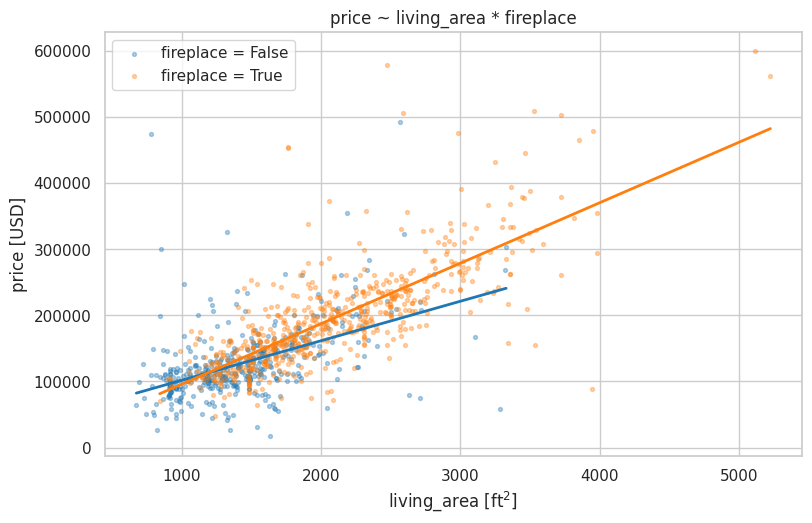

                         interaction model  separate models
intercept, no fireplace       42179.745813     42179.745813
slope, no fireplace              59.743304        59.743304
intercept, fireplace           4564.299135      4564.299135
slope, fireplace                 91.469805        91.469805

s_n: interaction = 49321.2, no fireplace = 48147.1, fireplace = 50105.8
                        interaction model  separate models
SE slope, no fireplace           5.257026         5.131878
SE slope, fireplace              3.005975         3.053790

residual sd by group (interaction model):
fireplace
False    48090.695788
True     50065.720016
dtype: float64


In [ ]:
# 1) Model matrix of living_area * fireplace
y_i, X_i = dmatrices('price ~ living_area * fireplace', data=df, return_type='dataframe')
print(list(X_i.columns), ' rank:', np.linalg.matrix_rank(X_i.to_numpy()))
print(X_i.head())

fit_int = smf.ols('price ~ living_area * fireplace', data=df).fit()
print(fit_int.summary().tables[1])
b0, bf, ba, bi = fit_int.params['Intercept'], fit_int.params['fireplace[T.True]'], \
                 fit_int.params['living_area'], fit_int.params['living_area:fireplace[T.True]']
print(f'\nno fireplace: price = {b0:.1f} + {ba:.2f} * area')
print(f'fireplace   : price = {b0 + bf:.1f} + {ba + bi:.2f} * area')

# 2) t-test of the interaction
tval = fit_int.tvalues['living_area:fireplace[T.True]']
pval = fit_int.pvalues['living_area:fireplace[T.True]']
print(f'\nH0: interaction = 0,  t = {tval:.3f},  df = {int(fit_int.df_resid)},  p = {pval:.4f}')

fig, ax = plt.subplots(figsize=(9, 5.5))
for fp, col in [(False, 'tab:blue'), (True, 'tab:orange')]:
    sub = df[df['fireplace'] == fp]
    ax.scatter(sub['living_area'], sub['price'], s=8, alpha=0.35, color=col, label=f'fireplace = {fp}')
    xs = np.linspace(sub['living_area'].min(), sub['living_area'].max(), 50)
    ax.plot(xs, fit_int.predict(pd.DataFrame({'living_area': xs, 'fireplace': fp})), color=col, lw=2)
ax.set(xlabel='living_area [ft$^2$]', ylabel='price [USD]', title='price ~ living_area * fireplace')
ax.legend()
plt.show()

# 3) Two separate regressions
fit_no = smf.ols('price ~ living_area', data=df[~df['fireplace']]).fit()
fit_yes = smf.ols('price ~ living_area', data=df[df['fireplace']]).fit()
print(pd.DataFrame({
    'interaction model': [b0, ba, b0 + bf, ba + bi],
    'separate models': [fit_no.params['Intercept'], fit_no.params['living_area'],
                        fit_yes.params['Intercept'], fit_yes.params['living_area']]},
    index=['intercept, no fireplace', 'slope, no fireplace', 'intercept, fireplace', 'slope, fireplace']))

# 4) s_n and standard errors
print(f"\ns_n: interaction = {np.sqrt(fit_int.scale):.1f}, no fireplace = {np.sqrt(fit_no.scale):.1f}, "
      f"fireplace = {np.sqrt(fit_yes.scale):.1f}")
se_int_no = fit_int.bse['living_area']
cv = fit_int.cov_params()
ia = 'living_area:fireplace[T.True]'
se_int_yes = np.sqrt(cv.loc['living_area', 'living_area'] + cv.loc[ia, ia] + 2 * cv.loc['living_area', ia])
print(pd.DataFrame({'interaction model': [se_int_no, se_int_yes],
                    'separate models': [fit_no.bse['living_area'], fit_yes.bse['living_area']]},
                   index=['SE slope, no fireplace', 'SE slope, fireplace']))
res_sd = fit_int.resid.groupby(df['fireplace']).std()
print('\nresidual sd by group (interaction model):')
print(res_sd)

**1.**
- Sloupce: $\mathbf{1}$, $f$ (dummy krb), $a$ (`living_area`), $a \cdot f$.
- Bez krbu ($f = 0$): $\text{price} = \beta_0 + \beta_a a$. S krbem ($f = 1$): $\text{price} = (\beta_0 + \beta_f) + (\beta_a + \beta_{af})\,a$.
- $\beta_0$ [USD]: očekávaná cena domu bez krbu při nulové ploše (extrapolace).
- $\beta_f$ [USD]: rozdíl interceptů (s krbem − bez krbu) při nulové ploše. Efekt krbu závisí na ploše: $\beta_f + \beta_{af}\,a$.
- $\beta_a$ [USD/ft²]: cena za čtvereční stopu u domů bez krbu.
- $\beta_{af}$ [USD/ft²]: o kolik víc se platí za čtvereční stopu u domů s krbem.

**2.**
- $H_0: \beta_{af} = 0$ (stejná cena za ft²) proti $H_1: \beta_{af} \neq 0$.
- $T = \hat\beta_{af}/\mathrm{SE}(\hat\beta_{af}) \sim t(n-4)$ za $H_0$.
- $H_0$ zamítáme: domy s krbem mají vyšší cenu za ft².
- Přímky nejsou rovnoběžné a protínají se zhruba u $-\hat\beta_f/\hat\beta_{af} \approx 1\,200$ ft². U větších domů je krb spojen s vyšší cenou.

**3.**
- Oddělené regrese dávají přesně stejné intercepty i sklony jako přímky z modelu s interakcí.
- Sloupce $(1-f),\ a(1-f),\ f,\ af$ vzniknou z $\mathbf{1}, f, a, af$ regulární transformací, takže mají stejný $\mathcal{M}(\mathbf{X})$.
- Po seřazení řádků podle skupin je tato matice blokově diagonální. $\mathbf{X}^T\mathbf{X}$ je pak také blokově diagonální a normální rovnice se rozpadnou na dvě nezávislé úlohy, tedy dvě oddělené regrese. Stejné jsou i $\widehat{\mathbf{y}}$ a $\widehat{\mathbf{e}}$.

**4.**
- Bloky $(\mathbf{X}^T\mathbf{X})^{-1}$ jsou v obou přístupech stejné, takže SE sklonů se liší jen přes $s_n$: $\mathrm{SE}_{int}/\mathrm{SE}_{sep} = s_{pooled}/s_{group}$.
- Model s interakcí předpokládá společné $\sigma^2$ pro obě skupiny (pooled odhad, $n-4$ stupňů volnosti). Oddělené modely odhadují $\sigma^2$ v každé skupině zvlášť.
- Reziduální sd ve skupinách jsou si blízko, proto bych volil model s interakcí: jeden model, přímý test rozdílu sklonů, víc stupňů volnosti.
- Ověřit: shodu rozptylů ve skupinách (F-test, Levene) a graf reziduí vs. fitted podle skupin. Pravděpodobnější je heteroskedasticita rostoucí s plochou/cenou, což může vést na $\log(\text{price})$.

## Task 11 - Team summary
In 6 to 10 sentences, as a team: what did the linear-algebra view explain in these data that the `summary()` table alone would not have shown? Which numerical method would you trust for least squares and why? Name one thing in the data you would report to whoever prepared them.

- Lineárně-algebraický pohled vysvětlil paradox ložnic: podle FWL je $\hat\beta_{bed}$ efekt jen té části variability ložnic, která je kolmá na ostatní regresory. `summary()` ukáže jen záporné číslo bez důvodu.
- Ukázal, že důležitý je prostor $\mathcal{M}(\mathbf{X})$, ne konkrétní sloupce: reparametrizace, dvě dummy bez interceptu i interakce vs. oddělené regrese dávají stejné $\mathbf{H}$, $\widehat{\mathbf{y}}$ a $R^2$, mění se jen $\widehat{\boldsymbol\beta}$.
- U singulární matice rozlišil identifikované kombinace parametrů od neidentifikovaných a vysvětlil, že o interceptu rozhoduje $\mathbf{1} \in \mathcal{M}(\mathbf{X})$.
- SVD ukázalo, který směr v datech zvětšuje rozptyl $\hat\beta_{bed}$. Kladná korelace regresorů vede na zápornou korelaci odhadů, což simulace potvrdila.
- Leverage $h_{ii}$ našly podezřelá data ještě před použitím $\mathbf{y}$ a ukázalo se, že na nich stojí celý efekt stáří.
- Pro nejmenší čtverce bychom věřili QR rozkladu (případně SVD) na standardizovaných/centrovaných regresorech: nesestavuje $\mathbf{X}^T\mathbf{X}$ (to by umocnilo $\kappa$ na druhou) a nic tiše neprahuje.
- Default pinv ve `statsmodels` u špatně škálovaných sloupců tiše ořízne hodnost (polynomy). Vždy je proto potřeba kontrolovat $\kappa(\mathbf{X})$ a `df_model`.
- Autorovi dat bychom nahlásili extrémní hodnoty `age` (domy starší než ~150 let, ojedinělé a s nepravděpodobnými kombinacemi ostatních proměnných) a zeptali se, jak je stáří definováno.
